In [1]:
from pathlib import Path
import os, csv, json, sys, html
import numpy as np
from IPython.display import display, HTML, Image
# Keep research_set.py and base_set.py beside this notebook.
from research_set import Config, METHODS, run_experiment

MODE = "pilot"  # smoke / pilot / full
RUN_TRAINING = False  # True runs/resumes; False inspects the delivered results.
cfg = Config.full() if MODE == "full" else Config.pilot() if MODE == "pilot" else Config()
DATA_DIR = Path(os.environ.get("SET_DATA_DIR", str(Path.cwd())))
if not (DATA_DIR / "samX.csv").exists():
    DATA_DIR = Path.cwd().parent  # Set SET_DATA_DIR when data are elsewhere.
METADATA = None  # Path to a verified row_index,split,group_id mapping, if available.
RESULT_DIR = Path(MODE + "_results")
print("Methods:", ", ".join(METHODS))
print("Mode:", MODE, "epochs:", cfg.epochs, "seeds:", cfg.seeds)


Methods: dense, lasso, group_lasso, static_sparse, fixed_set, set_lasso, gradient_set, adaptive_set, adaptive_gradient_set, adaptive_structured_set, fixed_group_set, adaptive_group_set
Mode: pilot epochs: 10 seeds: (11, 23, 37)


## Methods

Dense, LASSO, L21, static sparsity, SET, and adaptive variants. L21 groups hidden-neuron weights. Select settings using validation data only.


In [2]:
if RUN_TRAINING:
    rows, histories = run_experiment(DATA_DIR, RESULT_DIR, cfg, METADATA, resume=True)
else:
    if not (RESULT_DIR / "metrics.csv").exists():
        raise FileNotFoundError("No saved results. Set RUN_TRAINING=True or select a delivered mode.")
    with (RESULT_DIR / "metrics.csv").open() as handle:
        saved_rows = list(csv.DictReader(handle))
    rows = []
    for record in saved_rows:
        converted = {}
        for key, value in record.items():
            try: converted[key] = float(value)
            except ValueError: converted[key] = value
        rows.append(converted)
configuration = json.loads((RESULT_DIR / "config.json").read_text())
print("Completed model runs:", len(rows))
print(json.dumps(configuration["data"], indent=2))


Completed model runs: 288
{
  "input_rows": 10000,
  "unique_input_windows": 9107,
  "removed_duplicates": {
    "test": 137,
    "validation": 126,
    "train": 630
  },
  "counts": {
    "test": 1863,
    "validation": 1474,
    "train": 5770
  },
  "positive_rates": {
    "test": [
      0.5319377183914185,
      0.5469672679901123,
      0.5421363115310669,
      0.5163714289665222
    ],
    "validation": [
      0.5312076210975647,
      0.5502035021781921,
      0.5393487215042114,
      0.5373134613037109
    ],
    "train": [
      0.535355269908905,
      0.549220085144043,
      0.5514731407165527,
      0.5329289436340332
    ]
  },
  "mean": 587.0359497070312,
  "scale": 927.8833618164062,
  "samX_sha256": "cc1f2501e60621629dc4c03cb3500273d9d9d2d14738e713e4e217a7c34f26bb",
  "samY_sha256": "253a21f3d90f4572ddf92c5a69e338ba6948c6292f4194b658a77aed8fd76c3a",
  "metadata_sha256": null,
  "provenance": "CSV-only: source-window overlap and unseen-house generalization are NOT ve

## Results

Report test F1, model size, and latency. Error bars show variation across seeds. Fewer connections do not guarantee faster execution.


Backbone,Method,Macro F1 mean ± SD,Neurons,Dense MACs,Weights KiB,Batch latency ms
DNN,dense,0.8008 ± 0.0028,100.0,62020,242.7,0.162
DNN,lasso,0.7989 ± 0.0035,100.0,62020,242.7,0.160
DNN,group_lasso,0.8013 ± 0.0056,100.0,62020,242.7,0.162
DNN,static_sparse,0.7988 ± 0.0016,100.0,62020,242.7,0.161
DNN,fixed_set,0.7971 ± 0.0059,100.0,62020,242.7,0.161
DNN,set_lasso,0.7936 ± 0.0052,100.0,62020,242.7,0.161
DNN,gradient_set,0.7935 ± 0.0018,100.0,62020,242.7,0.162
DNN,adaptive_set,0.7990 ± 0.0027,100.0,62020,242.7,0.162
DNN,adaptive_gradient_set,0.7952 ± 0.0014,100.0,62020,242.7,0.161
DNN,adaptive_structured_set,0.7904 ± 0.0039,76.3,47347,185.3,0.150


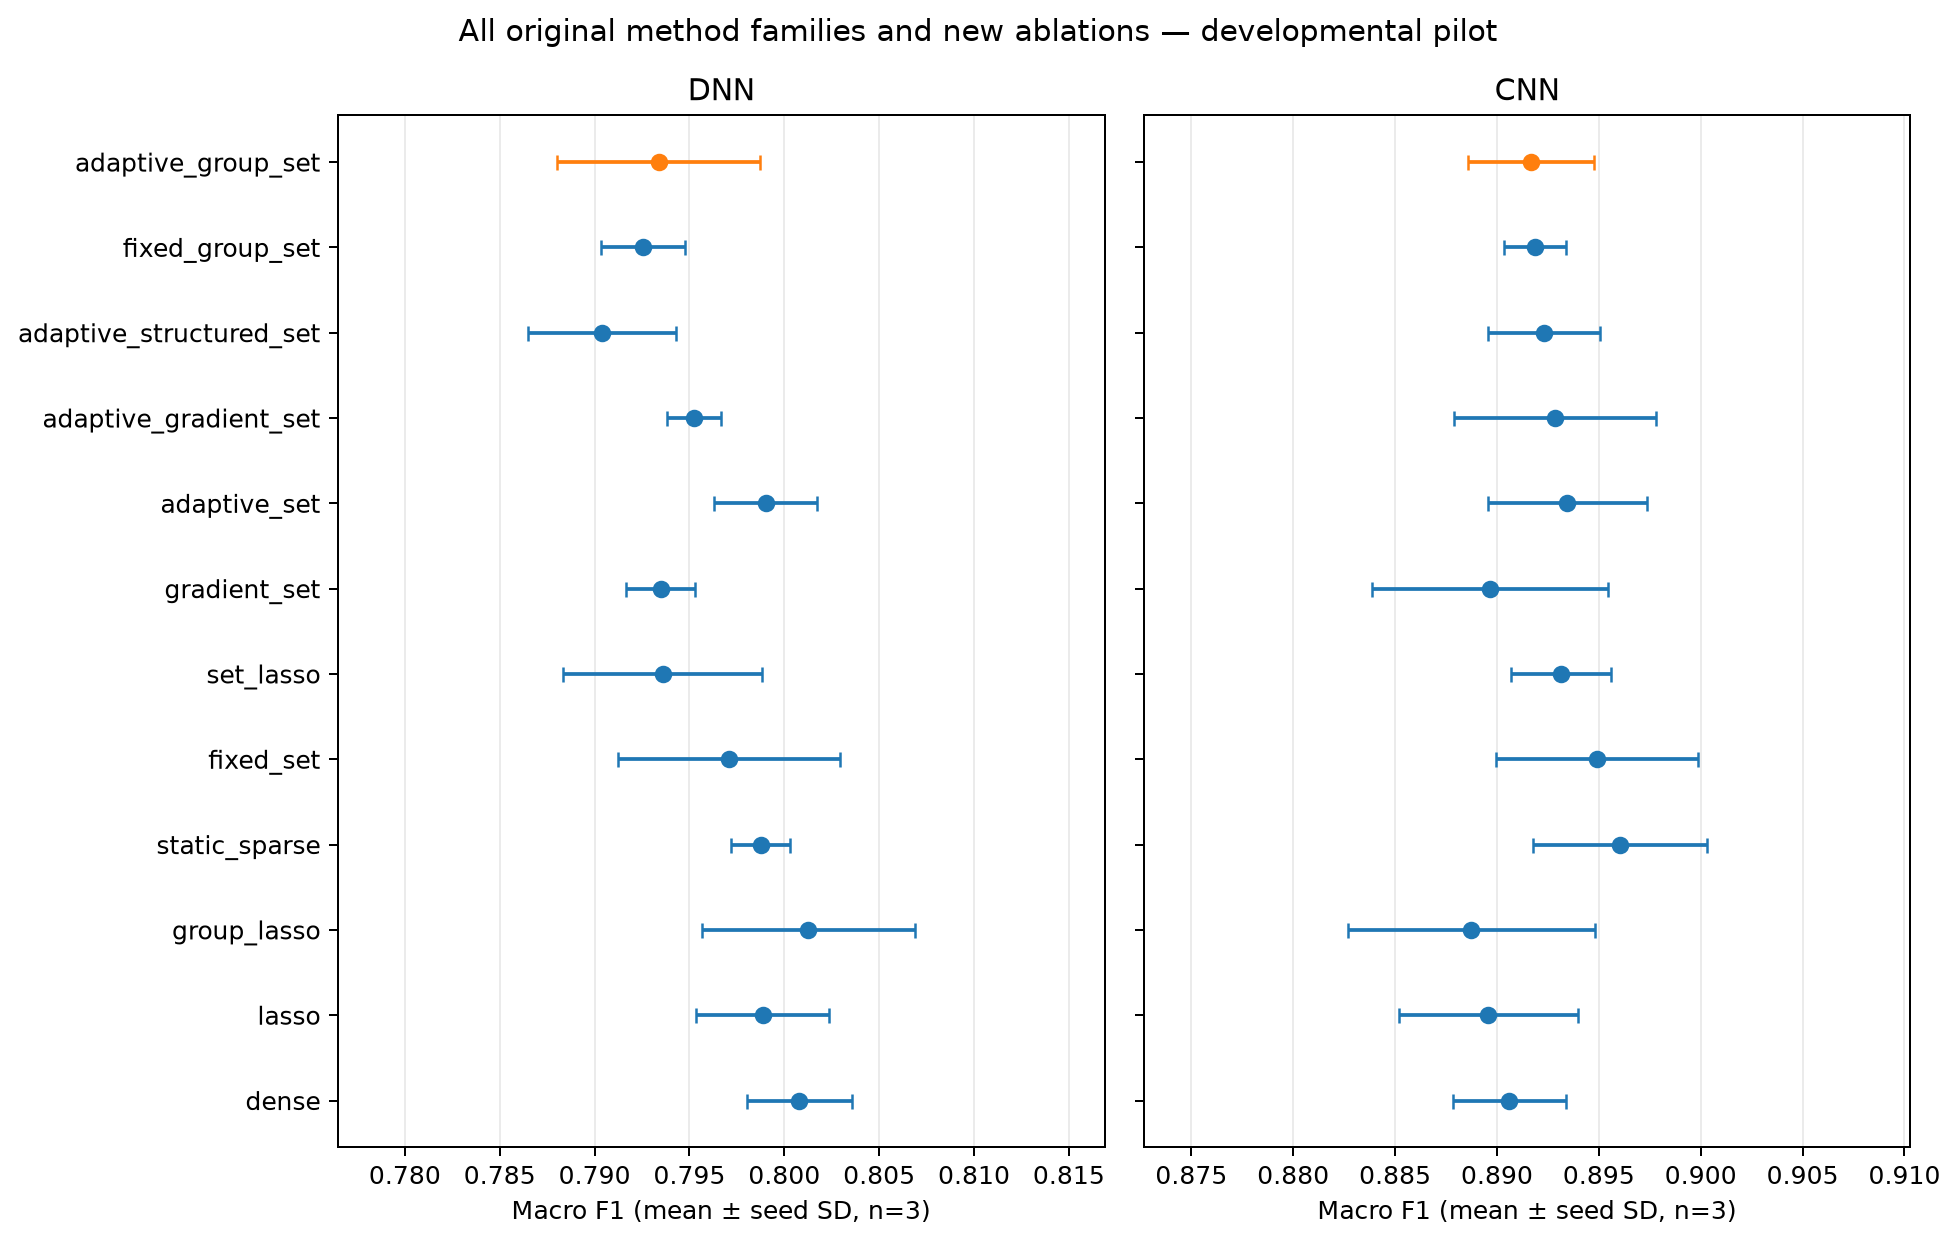

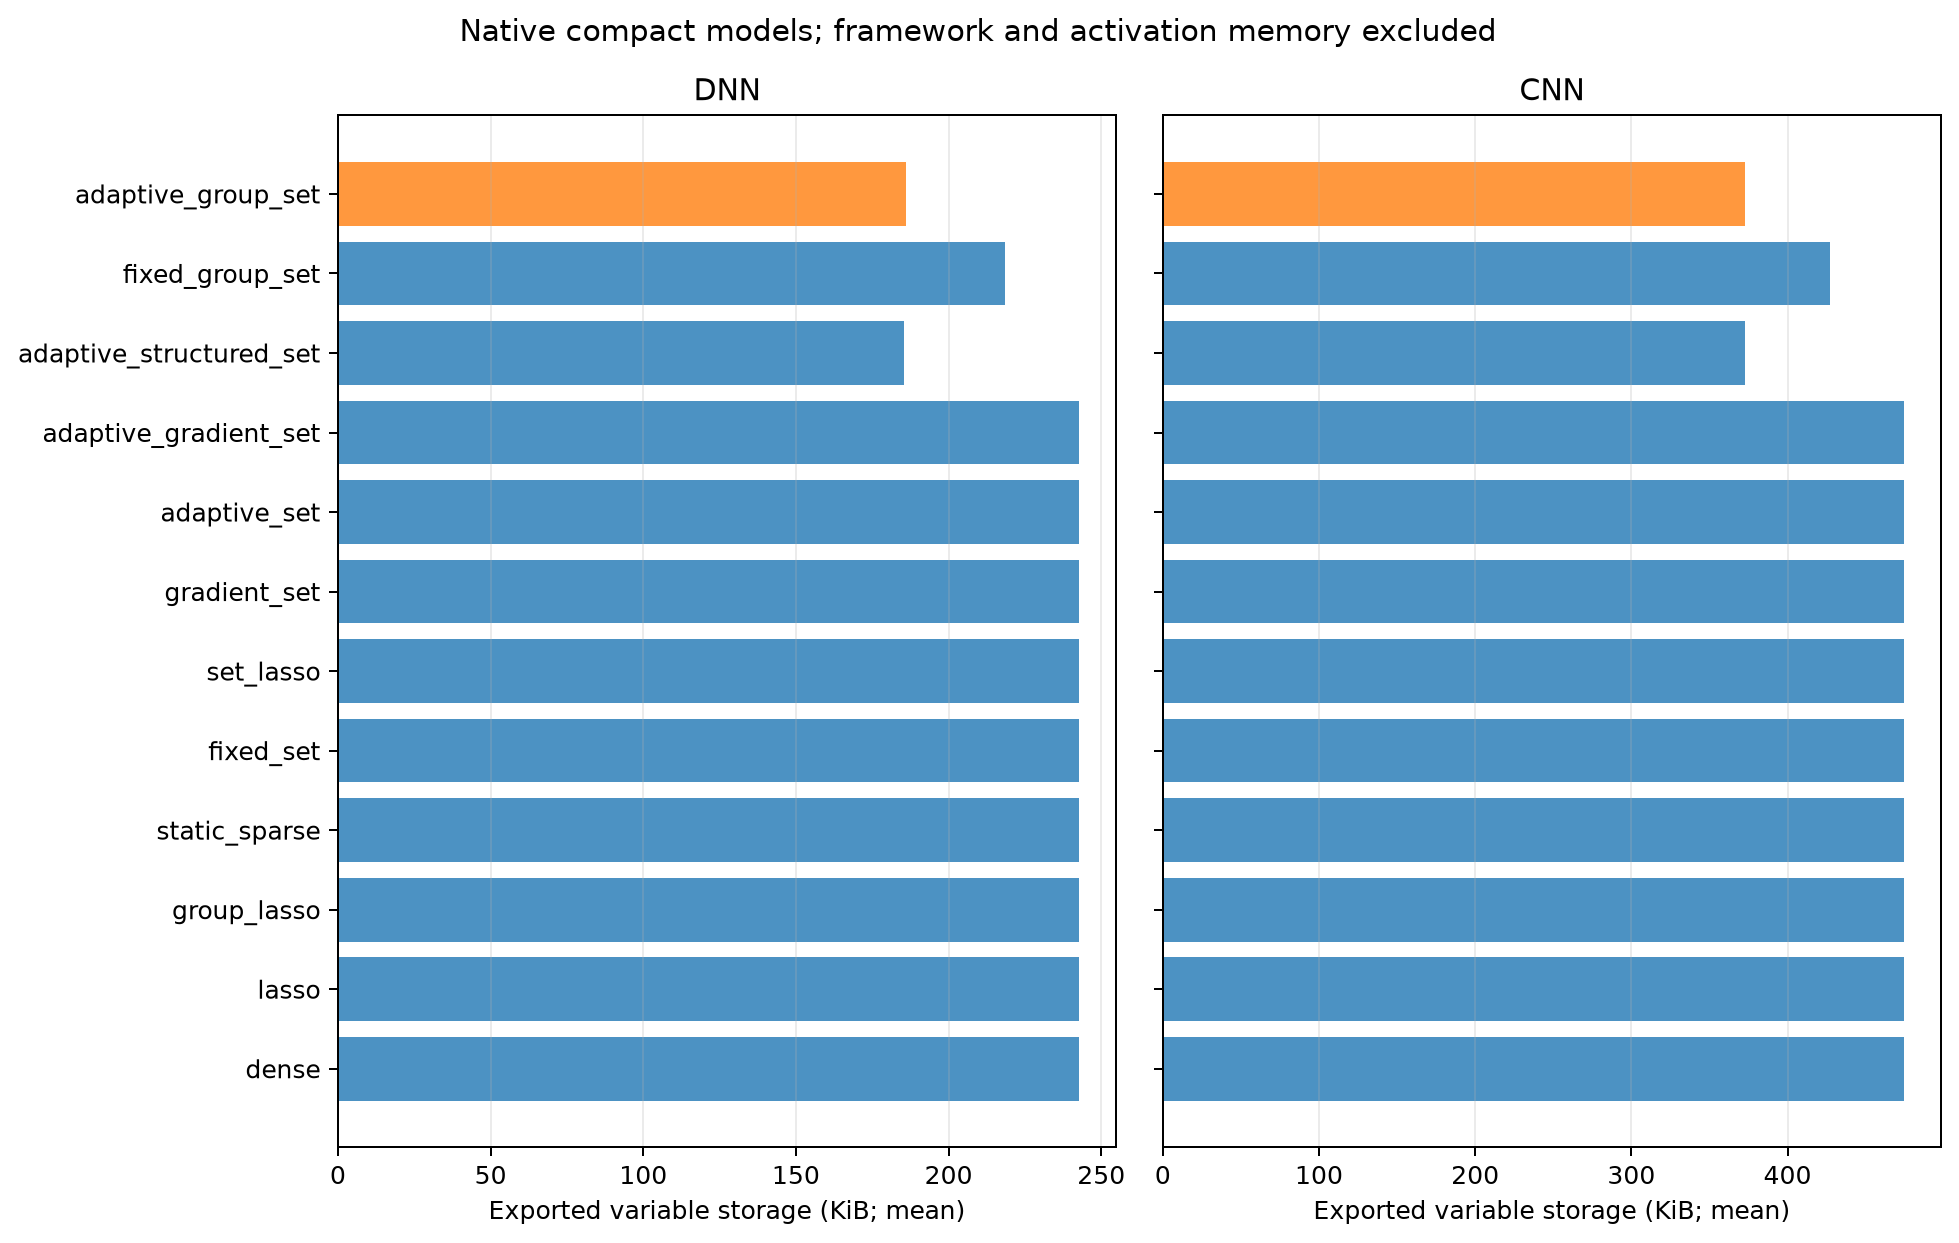

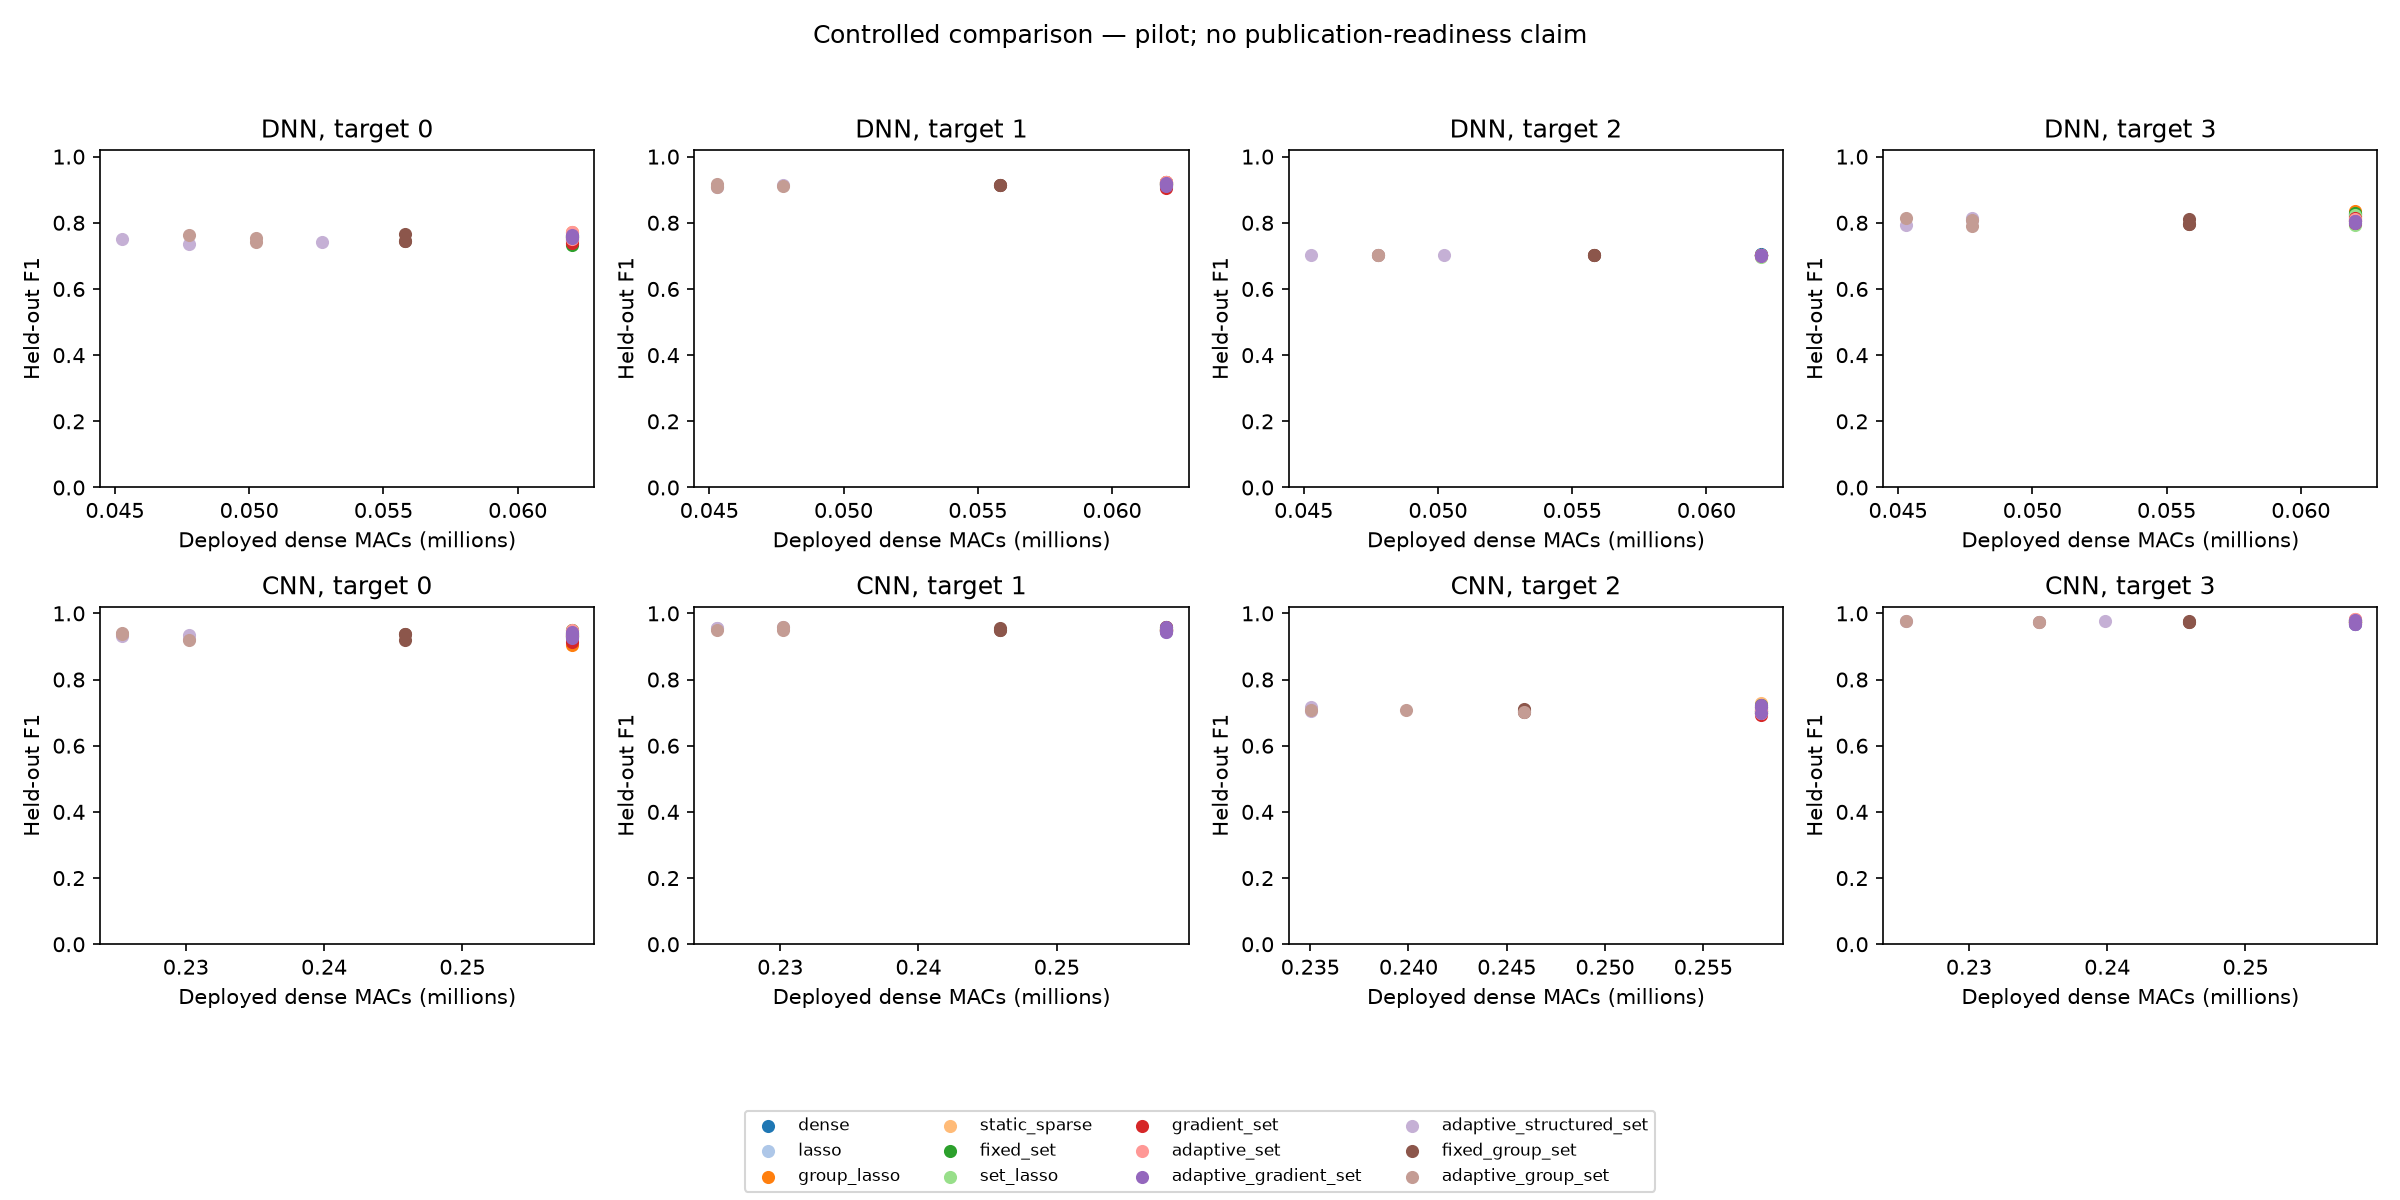

In [3]:
def table(headers, records):
    markup = "<table><tr>" + "".join("<th>"+html.escape(str(x))+"</th>" for x in headers) + "</tr>"
    for record in records:
        markup += "<tr>" + "".join("<td>"+html.escape(str(x))+"</td>" for x in record) + "</tr>"
    display(HTML(markup + "</table>"))
summary = []
for architecture in cfg.architectures:
    for method in cfg.methods:
        values = [r for r in rows if r["architecture"] == architecture and r["method"] == method]
        per_seed = []
        for seed in sorted({r["seed"] for r in values}):
            sample = [r for r in values if r["seed"] == seed]
            per_seed.append(np.mean([r["f1"] for r in sample]))
        if not per_seed: continue
        summary.append([architecture, method,
            f"{np.mean(per_seed):.4f} ± {np.std(per_seed, ddof=1) if len(per_seed)>1 else 0:.4f}",
            f"{np.mean([r['selected_neurons'] for r in values]):.1f}",
            f"{np.mean([r['compact_dense_macs'] for r in values]):.0f}",
            f"{np.mean([r['compact_weight_bytes'] for r in values])/1024:.1f}",
            f"{np.mean([r['compact_latency_median_ms'] for r in values]):.3f}"])
table(["Backbone", "Method", "Macro F1 mean ± SD", "Neurons", "Dense MACs", "Weights KiB", "Batch latency ms"], summary)
display(Image(filename=str(RESULT_DIR / "macro_f1_comparison.png")))
display(Image(filename=str(RESULT_DIR / "compact_storage_comparison.png")))
display(Image(filename=str(RESULT_DIR / "deployment_tradeoff.png")))


## Uncertainty

Compare matched seeds and test groups. Three seeds give limited evidence. Source-window overlap is unverified.


In [4]:
with (RESULT_DIR / "paired_uncertainty.csv").open() as handle:
    comparisons = list(csv.DictReader(handle))
focus = [r for r in comparisons if r["baseline"] in {"dense", "fixed_set", "fixed_group_set"}]
table(["Backbone", "Target", "Baseline", "ΔF1", "Paired 95% interval", "Holm p"], [
    [r["architecture"], r["target"], r["baseline"], f"{float(r['mean_f1_difference']):+.4f}",
     f"[{float(r['bootstrap_ci_low']):+.4f}, {float(r['bootstrap_ci_high']):+.4f}]",
     f"{float(r['holm_adjusted_p']):.4f}"] for r in focus])
status = json.loads((RESULT_DIR / "research_status.json").read_text())
print(json.dumps(status, indent=2))


Backbone,Target,Baseline,ΔF1,Paired 95% interval,Holm p
DNN,0,dense,-0.0017,"[-0.0144, +0.0098]",1.0000
DNN,0,fixed_set,+0.0028,"[-0.0109, +0.0156]",1.0000
DNN,0,fixed_group_set,+0.0013,"[-0.0115, +0.0132]",1.0000
DNN,1,dense,-0.0064,"[-0.0151, +0.0011]",1.0000
DNN,1,fixed_set,-0.0054,"[-0.0125, +0.0025]",1.0000
DNN,1,fixed_group_set,-0.0009,"[-0.0083, +0.0063]",1.0000
DNN,2,dense,-0.0003,"[-0.0024, +0.0018]",1.0000
DNN,2,fixed_set,+0.0002,"[-0.0034, +0.0030]",1.0000
DNN,2,fixed_group_set,-0.0005,"[-0.0018, +0.0008]",1.0000
DNN,3,dense,-0.0214,"[-0.0381, -0.0055]",1.0000


{
  "mode": "pilot",
  "completed_runs": 288,
  "seeds": [
    11,
    23,
    37
  ],
  "publication_ready": false,
  "limitations": [
    "These are synthetic-window presence-classification experiments, not power disaggregation.",
    "Source-window/house independence requires verification against source data.",
    "Masked training uses dense kernels; topology updates and candidate gradients add cost.",
    "Gradient regrowth is RigL-inspired, not an exact RigL reproduction.",
    "Proposed adaptive structured combination has not been established as literature-novel.",
    "Pilot and smoke modes are developmental; tuning after observing them must be disclosed.",
    "Seed/bootstrap uncertainty is conditional on these evaluation data.",
    "Native compact inference removes mask operations for ALL methods; unstructured zeros remain dense.",
    "Timing reflects this host only; independent hardware replication is required."
  ],
  "primary_metric": "Validation-thresholded test F1; als